### Problem 12 : Barren Plateaus - why you cannot just add more qubits

Problems 10 and 11 both stalled around 85%, and the obvious classical instinct kicks in : *make the
model bigger*. More qubits, more layers, more parameters. In classical deep learning that usually
works.

In quantum machine learning it can **destroy** your model. The phenomenon is called a
**barren plateau**, and it is arguably the single most important practical obstacle in the field.

**The result (McClean et al., 2018) :** for a sufficiently random parameterised circuit, the
variance of every cost-function gradient shrinks **exponentially with the number of qubits** :

**Var[ ∂C/∂θ ] ∈ O( 2^(−n) )**

The gradient is not biased - its *mean* is zero, which is fine - it is that the whole landscape
becomes **flat**. Everywhere you look, the cost is essentially the same value, and any gradient you
measure is buried under shot noise. The optimizer has nothing to follow.

**TASK :** Measure this decay yourself. Then see what it means in practice when you only have a
finite number of shots.

📄 Original paper : https://www.nature.com/articles/s41467-018-07090-6

In [1]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

#### The experiment

The recipe is simple and it is exactly what the paper does :

1. Pick a number of qubits n.
2. Build a random parameterised circuit - we use `StronglyEntanglingLayers`, the same ansatz as
   Problem 10.
3. Sample many **random** parameter settings (this is the key : we are asking what the landscape
   looks like *at initialisation*, before any training).
4. For each one, compute the exact gradient with respect to **one fixed parameter**.
5. Report the **variance** of those gradients.

Then repeat for n = 2, 3, 4, … and watch what happens.

In [2]:
def gradient_variance(n_qubits, n_layers=5, n_samples=80, seed=0):
    """Variance of one gradient component over randomly initialised circuits."""
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev)
    def circuit(weights):
        qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
        return qml.expval(qml.PauliZ(0) @ qml.PauliZ(1))     # a simple 2-local cost

    grad_fn = qml.grad(circuit)
    rng = np.random.default_rng(seed)

    gradients = []
    for _ in range(n_samples):
        weights = np.array(
            rng.uniform(0, 2 * np.pi, (n_layers, n_qubits, 3)), requires_grad=True
        )
        # always differentiate the SAME parameter: middle layer, qubit 0, the RY angle
        gradients.append(grad_fn(weights)[n_layers // 2, 0, 1])

    return float(np.var(gradients)), gradients

In [3]:
qubit_range = [2, 3, 4, 5, 6, 7, 8]
variances = []

for n in qubit_range:
    var, _ = gradient_variance(n)
    variances.append(var)
    print(f"{n} qubits -> Var[dC/dtheta] = {var:.6f}")

2 qubits -> Var[dC/dtheta] = 0.125825


3 qubits -> Var[dC/dtheta] = 0.044129


4 qubits -> Var[dC/dtheta] = 0.033403


5 qubits -> Var[dC/dtheta] = 0.010255


6 qubits -> Var[dC/dtheta] = 0.002722


7 qubits -> Var[dC/dtheta] = 0.004059


8 qubits -> Var[dC/dtheta] = 0.002242


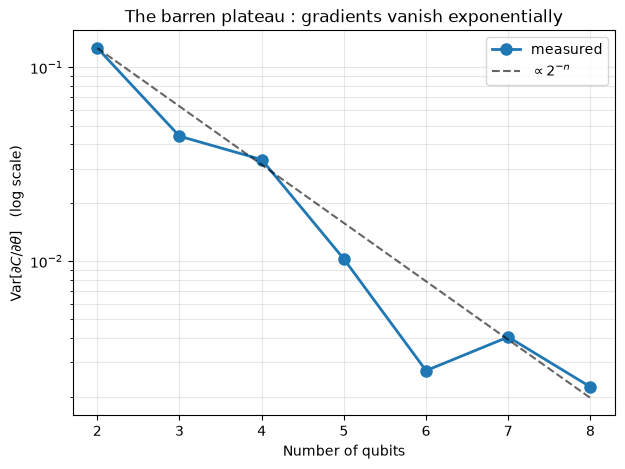

Measured shrink factor per extra qubit: 1.96x


In [4]:
# A log-scale plot turns an exponential decay into a straight line
plt.figure(figsize=(7, 5))
plt.semilogy(qubit_range, variances, 'o-', linewidth=2, markersize=8, label='measured')

# reference line: pure 2^-n decay, anchored at the first point
reference = [variances[0] * 2.0 ** (-(n - qubit_range[0])) for n in qubit_range]
plt.semilogy(qubit_range, reference, 'k--', alpha=0.6, label=r'$\propto 2^{-n}$')

plt.xlabel("Number of qubits")
plt.ylabel(r"Var$[\partial C / \partial \theta]$   (log scale)")
plt.title("The barren plateau : gradients vanish exponentially")
plt.legend(); plt.grid(alpha=0.3, which='both'); plt.show()

decay = (variances[0] / variances[-1]) ** (1 / (qubit_range[-1] - qubit_range[0]))
print(f"Measured shrink factor per extra qubit: {decay:.2f}x")

The measured points sit close to the dashed 2^(−n) reference line. Going from 2 to 8 qubits -
a tiny circuit by any standard - already shrinks the gradient variance by roughly **two orders of
magnitude**.

Note also that the *mean* gradient is about zero in every case. The problem is not that the
gradient points the wrong way; it is that there is nothing to point at.

In [5]:
# Confirm: the mean is ~0 everywhere, it is the spread that collapses
for n in [2, 5, 8]:
    var, grads = gradient_variance(n, n_samples=80)
    print(f"{n} qubits | mean {np.mean(grads):+.5f} | std {np.std(grads):.5f}")

2 qubits | mean +0.00945 | std 0.35472


5 qubits | mean -0.00804 | std 0.10127


8 qubits | mean +0.00666 | std 0.04735


#### Why this is fatal in practice : shots

On a simulator we computed *exact* gradients, so a tiny gradient is still a usable gradient. On real
hardware (and on any shot-based simulation) every expectation value is estimated from a finite
number of measurements, and that estimate carries statistical noise of about **1/√shots**.

So the question is not "is the gradient small?" but **"is the gradient bigger than the noise?"**
To resolve a gradient of size g you need roughly

**shots ≳ 1 / g²**

Let us watch the signal-to-noise ratio collapse.

In [6]:
def gradient_snr(n_qubits, n_layers=5, shots=1000, repeats=15, seed=7):
    """Compare the exact gradient against noisy shot-based estimates of it."""
    rng = np.random.default_rng(seed)
    weights = np.array(
        rng.uniform(0, 2 * np.pi, (n_layers, n_qubits, 3)), requires_grad=True
    )

    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, diff_method="parameter-shift")
    def circuit(w):
        qml.StronglyEntanglingLayers(w, wires=range(n_qubits))
        return qml.expval(qml.PauliZ(0) @ qml.PauliZ(1))

    idx = (n_layers // 2, 0, 1)
    exact = float(qml.grad(circuit)(weights)[idx])

    noisy_circuit = qml.set_shots(circuit, shots=shots)       # now every run is sampled
    grad_fn = qml.grad(noisy_circuit)
    estimates = [float(grad_fn(weights)[idx]) for _ in range(repeats)]

    noise = float(np.std(estimates))
    print(f"{n_qubits} qubits | exact gradient {exact:+.4f} | shot noise +/- {noise:.4f} "
          f"| signal-to-noise {abs(exact) / noise:.1f}x")


gradient_snr(2)
gradient_snr(8)

2 qubits | exact gradient -0.3399 | shot noise +/- 0.0191 | signal-to-noise 17.8x


8 qubits | exact gradient +0.0656 | shot noise +/- 0.0197 | signal-to-noise 3.3x


At 2 qubits the gradient stands well clear of the noise and the optimizer can follow it. At 8
qubits the signal has shrunk while the noise has not, and the ratio collapses. Push to 30 or 50
qubits - the regime where quantum computers might actually be useful - and you would need
astronomically many shots per step. **The model becomes untrainable long before it becomes useful.**

#### What people actually do about it

There is no single cure, but there is a toolbox, and every item in it is about **not letting the
circuit be random** :

| Strategy | Idea |
|---|---|
| **Local cost functions** | Measure few-qubit observables (⟨Z₀Z₁⟩) rather than global ones (the projector onto ∣00…0⟩). Global costs plateau even for shallow circuits. |
| **Shallow, structured ansätze** | Keep depth low and hardware-motivated. Depth is what makes a circuit random enough to plateau. |
| **Smart initialisation** | Start near the identity (e.g. tiny random angles - note Problem 10 used `np.random.normal(0, 0.1)`, not uniform over 2π) or use identity-block initialisation. |
| **Layer-by-layer training** | Train one layer, freeze it, add the next. Each sub-problem stays small. |
| **Problem-inspired ansätze** | Build the circuit from the physics (UCCSD for chemistry, the QAOA ansatz for optimization) instead of a generic entangler. Problems 15 and 16 do exactly this. |
| **Data re-uploading** | Re-inject the data between layers so the circuit stays structured. That is Problem 13. |

#### Key Takeaways :
- Random deep circuits have **exponentially vanishing gradient variance** in the qubit count.
- The mean gradient is zero - the landscape is *flat*, not misleading.
- With finite shots, a flat landscape is indistinguishable from noise, so training stops working.
- **Bigger is not better in QML.** Structure beats size.

#### TASK :
1. Re-run `gradient_variance` with `n_layers = 1` and `n_layers = 20`. Depth saturates much faster
   than qubit count - once the circuit is "random enough" (a so-called 2-design), adding layers
   changes little. At what depth does the variance stop moving?
2. Change the observable to a **global** cost - the product of PauliZ over *all* qubits - and repeat
   the sweep. Compare the two curves.
3. Sample the initial weights from `rng.normal(0, 0.05, ...)` instead of `uniform(0, 2*pi, ...)`.
   The variance should improve noticeably. Explain why in terms of how far the circuit is from the
   identity.